# Analysis of Used Car Pricing in Kazakhstan (kolesa.kz)
---

## 1. Research Motivation and Research Questions (Topic Motivation)

### 1.1. Practical and Economic Relevance for Kazakhstan
The used car market in Kazakhstan is one of the biggest and most active consumer markets in the country. Its main platform is **Kolesa.kz**. In Kazakhstan, a car is often more than a way to get around. It is also a kind of financial reason. People use it to protect their savings from inflation and from changes in the tenge exchange rate.

But the market has a big structural problem: information asymmetry.
1. **Sellers** often set prices that are too high. They are emotionally attached to their car, or they think it is in "perfect condition" without real reason.
2. **Buyers** have no clear price benchmarks, so they risk overpaying.

A regression model helps to solve this - it can estimate the **Fair Market Value** of a car using objective parameters.

### 1.2. Research Questions
This project tests five main question about the Kazakhstan car market:
1. **Depreciation rate:** By how many percent does a car's market price fall on average with each extra year of age (X1) and each extra 10,000 km of mileage (X2)? Is depreciation exactly exponential, or is it convex (the drop slows down over time)?
2. **"Japan / Toyota Premium":** Is there a statistically significant premium for Japanese cars compared with European, Korean, Chinese and local (CIS) brands, with the same conditions (same age, mileage, body type and engine size)?
3. **Transmission and options premium:** How much does an automatic transmission (automatic, CVT or robotic) raise the price of a car compared with a manual gearbox?
4. **Premium segment (logistic regression):** Which characteristics raise the odds that a car is in the most expensive 25% of the market?
5. **Regularization:** Do Ridge and Lasso predict prices better than ordinary OLS?

In [1]:
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
from sklearn.model_selection import KFold, train_test_split
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score, roc_curve, roc_auc_score)


warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.titlesize'] = 13

SEED = 42
SCRAPE_YEAR = 2025

## 2. Data & Feature Extraction

Instead of ready-made ideal training datasets, we use a sample of real ads from the **Kolesa.kz** portal (N = 3,999 rows). Real data has natural market noise. We need to extract hidden predictors from the text field desc (body type, exact engine volume, fuel type, transmission, claimed mileage, options).

In [2]:
raw_df = pd.read_csv('cars_kolesa_parsed.csv')

display(raw_df.head(3))

,name,price,price_raw,desc,link,brand,model,condition,year,mileage_km,engine_liters,fuel,transmission,drive
0,Kia K5,7300000,7 300 000 ₸,"2015 г., Б/у седан, 2 л, газ, КПП автомат, с п...",https://kolesa.kz/a/show/206857918?search_id=6...,Kia,K5,used,2015,94000.0,NaN,gas,automatic,NaN
1,Lexus RX 300 F Sport Design,17750000,17 750 000 ₸,"2018 г., Б/у кроссовер, 2 л, бензин, КПП автом...",https://kolesa.kz/a/show/205587148?search_id=6...,Lexus,RX 300 F Sport Design,used,2018,148057.0,NaN,petrol,automatic,NaN
2,Li L9 Ultra,31500000,31 500 000 ₸,"На заказ, 2025 г., новый кроссовер, 1.5 л, бен...",https://kolesa.kz/a/show/184418014?search_id=6...,Li,L9 Ultra,new,2025,50.0,1.5,petrol,automatic,NaN


### 2.1. Variables and data types

- **Target variable (Y):** price - numeric, continuous.
- **Numeric:** year (discrete), mileage_km, engine_liters (continuous).
- **Categorical:** brand, model, condition, fuel, transmission, drive.
- **Text:** name, desc, link, price_raw. The field desc is used to extract hidden predictors (Section 2.2).

In [3]:
var_overview = pd.DataFrame({
    'dtype': raw_df.dtypes.astype(str),
    'Missing': raw_df.isna().sum(),
    'Missing, %': (raw_df.isna().mean() * 100).round(1),
    'Unique values': raw_df.nunique()
})
print(f'Raw data: {raw_df.shape[0]} rows, {raw_df.shape[1]} columns')
display(var_overview)

Raw data: 3999 rows, 14 columns


,dtype,Missing,"Missing, %",Unique values
name,object,0,0.0,729
price,int64,0,0.0,729
price_raw,object,0,0.0,729
desc,object,0,0.0,2909
link,object,0,0.0,3999
brand,object,0,0.0,75
model,object,0,0.0,720
condition,object,0,0.0,2
year,int64,0,0.0,43
mileage_km,float64,1119,28.0,888


**Missing values:** drive is almost empty (99%) and is not used. mileage_km and engine_liters are missing in about 28-29% of ads, but this information is often written in desc, so we fill the gaps from the text (Section 2.2). Rows that still have no mileage are removed in Section 3.1.

### 2.2. Regular Expressions for parsing the desc field

The desc column contains parts separated by commas. We use strict regular expressions to get full matching accuracy without false positives.

In [4]:
BODY_DICT = {
    'седан': 'sedan', 'кроссовер': 'crossover', 'хэтчбек': 'hatchback',
    'универсал': 'wagon', 'лифтбек': 'liftback', 'внедорожник': 'suv',
    'минивэн': 'minivan', 'микровэн': 'minivan', 'микроавтобус': 'minibus',
    'купе': 'coupe', 'пикап': 'pickup', 'кабриолет': 'convertible',
    'фургон': 'van', 'лимузин': 'limousine', 'хардтоп': 'hardtop'
}
FUEL_DICT = {
    'бензин': 'petrol', 'дизель': 'diesel', 'газ': 'lpg',
    'газ-бензин': 'lpg+petrol', 'гибрид': 'hybrid', 'электричество': 'electric'
}
KPP_DICT = {
    'механика': 'manual', 'автомат': 'automatic',
    'вариатор': 'cvt', 'робот': 'robot'
}

def parse_car_desc(desc):
    r = dict(on_order=False, year_d=np.nan, cond_d=None, body=None, engine_d=np.nan,
             fuel_d=None, trans_d=None, mileage_d=np.nan, right_hand=False, metallic=False)
    if not isinstance(desc, str):
        return r
    for s in (x.strip() for x in desc.split(',')):
        low = s.lower()
        if low == 'на заказ':
            r['on_order'] = True; continue
        if re.fullmatch(r'(19|20)\d{2}\s*г\.?', s):
            r['year_d'] = int(s[:4]); continue
        m = re.fullmatch(r'(новый|б/у)\s+([а-яё]+)', low)
        if m:
            r['cond_d'] = 'new' if m.group(1) == 'новый' else 'used'
            r['body'] = BODY_DICT.get(m.group(2)); continue
        m = re.fullmatch(r'(\d+(?:[.,]\d+)?)\s*л', low)
        if m:
            r['engine_d'] = float(m.group(1).replace(',', '.')); continue
        if low in FUEL_DICT:
            r['fuel_d'] = FUEL_DICT[low]; continue
        m = re.fullmatch(r'кпп\s+([а-яё]+)', low)
        if m:
            r['trans_d'] = KPP_DICT.get(m.group(1)); continue
        m = re.fullmatch(r'(\d+(?:[.,]\d+)?)\s*тыс\.?\s*км', low)
        if m:
            r['mileage_d'] = float(m.group(1).replace(',', '.')) * 1000; continue
        m = re.fullmatch(r'(?:с пробегом\s+)?(\d[\d\s\u00a0]*)\s*км', low)
        if m:
            r['mileage_d'] = float(re.sub(r'\D', '', m.group(1))); continue
        if low == 'правый руль':
            r['right_hand'] = True
        if low.startswith('металлик'):
            r['metallic'] = True
    return r

parsed_series = raw_df['desc'].apply(parse_car_desc).apply(pd.Series)
df_merged = pd.concat([raw_df, parsed_series], axis=1)


def check_agreement(col_site, col_parsed):
    mask = col_site.notna() & col_parsed.notna()
    return pd.Series({
        'Compared rows': int(mask.sum()),
        'Match, %': round(100.0 * (col_site[mask] == col_parsed[mask]).mean(), 2)
    })

val_table = pd.DataFrame({
    'Year (year)': check_agreement(df_merged.year, df_merged.year_d),
    'Condition (condition)': check_agreement(df_merged.condition, df_merged.cond_d),
    'Transmission (transmission)': check_agreement(df_merged.transmission, df_merged.trans_d),
    'Engine volume (engine_l)': check_agreement(df_merged.engine_liters, df_merged.engine_d),
    'Mileage (mileage_km)': check_agreement(df_merged.mileage_km, df_merged.mileage_d),
}).T
print("Validation results of the parser regular expressions:")
display(val_table)

Validation results of the parser regular expressions:


,Compared rows,"Match, %"
Year (year),3999.0,100.00
Condition (condition),3999.0,100.00
Transmission (transmission),3999.0,99.95
Engine volume (engine_l),2841.0,100.00
Mileage (mileage_km),2877.0,100.00


## 3. Data Cleaning and Preprocessing

In [5]:
df_clean = df_merged.copy()
df_clean['listing_id'] = df_clean['link'].str.extract(r'/show/(\d+)')[0]

**Removing duplicate rows (because of ads)**

Paid ad promotions make the same cars appear many times. This make standard errors too small

In [6]:
df_clean = df_clean.drop_duplicates('listing_id', keep='first').reset_index(drop=True)

**Filtering prices < 300 000 tenge**

Prices below 300 thousand tenge are usually some deposit amounts or input error.

In [7]:
df_clean = df_clean[df_clean.price >= 300_000]

**Excluding cars older than 1990**

Cars older than 35 years follow other paterns, not the normal market depreciation of regular cars.

In [8]:
df_clean = df_clean[df_clean.year >= 1990]

**Excluding electric vehicles**

Electric cars do not have any engine volume in liters. Putting 0 liters would distort the estimate of the engine volume effect.

In [9]:
df_clean = df_clean[df_clean.fuel_d != 'electric']

**Filtering engine volume outside [0.6; 8.0]**

Removing artifacts (f.e like 0.1 L in hybrids) and missing engine volume values

In [10]:
df_clean['engine'] = df_clean['engine_liters'].fillna(df_clean['engine_d'])
df_clean = df_clean[df_clean.engine.between(0.6, 8.0)].copy()

In [11]:
# 6. age and milage
df_clean['age'] = SCRAPE_YEAR - df_clean['year']
df_clean['mileage'] = df_clean['mileage_km'].fillna(df_clean['mileage_d'])

In [12]:
# new cars and the ones without milage has 0 inside
new_cars_mask = (df_clean.condition == 'new') & df_clean.mileage.isna()
df_clean.loc[new_cars_mask, 'mileage'] = 0.0

In [13]:
# undreal milage (888, 666666) that has no useful meaning
bad_mileage_mask = ((df_clean.condition == 'used') & (df_clean.age >= 3) & (df_clean.mileage < 1000)) | (df_clean.mileage > 1_000_000)
df_clean.loc[bad_mileage_mask, 'mileage'] = np.nan

In [14]:
# scaling of milage
df_clean['mileage_10k'] = df_clean['mileage'] / 10000.0
df_clean['mileage_k'] = df_clean['mileage'] / 1000.0
df_clean['km_per_year'] = df_clean['mileage_k'] / df_clean['age'].clip(lower=1)

In [15]:
# format of categorical and dummy elements
df_clean['is_new'] = (df_clean.condition == 'new').astype(int)
df_clean['automatic'] = (df_clean.transmission != 'manual').astype(int)
df_clean['diesel'] = (df_clean.fuel_d == 'diesel').astype(int)
df_clean['hybrid'] = (df_clean.fuel_d == 'hybrid').astype(int)
df_clean['gas'] = df_clean.fuel_d.isin(['lpg', 'lpg+petrol']).astype(int)
df_clean['is_suv'] = df_clean.body.isin(['crossover', 'suv']).astype(int)
df_clean['is_comm'] = df_clean.body.isin(['minivan', 'minibus', 'van', 'pickup']).astype(int)

# classification for brands by the country of their origin
JAPAN = {'Toyota', 'Lexus', 'Nissan', 'Mitsubishi', 'Honda', 'Subaru', 'Infiniti', 'Mazda', 'Suzuki'}
KOREA = {'Hyundai', 'Kia', 'Daewoo', 'Genesis', 'SsangYong'}
EUROPE = {'Mercedes-Benz', 'BMW', 'Volkswagen', 'Audi', 'Renault', 'Opel', 'Skoda', 'Porsche', 'Volvo', 'Land Rover', 'Peugeot', 'Fiat', 'Bentley', 'Jaguar', 'Mini', 'MG'}
CHINA = {'AITO', 'BAIC', 'BYD', 'Baojun', 'Changan', 'Chery', 'Deepal', 'Denza', 'EXEED', 'FAW', 'Foton', 'GAC', 'Geely', 'Great Wall', 'Haval', 'Hongqi', 'JAC', 'Jaecoo', 'Jetour', 'Kaiyi', 'Leapmotor', 'Li', 'Lifan', 'Lynk', 'Niutron', 'OMODA', 'Roewe', 'Rox', 'Tank', 'Zeekr'}
CIS = {'ВАЗ', 'ГАЗ', 'ЗАЗ', 'УАЗ', 'Ravon'}
USA = {'Chevrolet', 'Ford', 'Cadillac', 'Chrysler', 'Dodge', 'Jeep', 'Hummer'}

df_clean['origin_japan'] = df_clean['brand'].isin(JAPAN).astype(int)
df_clean['origin_korea'] = df_clean['brand'].isin(KOREA).astype(int)
df_clean['origin_europe'] = df_clean['brand'].isin(EUROPE).astype(int)
df_clean['origin_china'] = df_clean['brand'].isin(CHINA).astype(int)
df_clean['origin_cis'] = df_clean['brand'].isin(CIS).astype(int)
df_clean['origin_usa'] = df_clean['brand'].isin(USA).astype(int)

In [16]:
for col in ['right_hand', 'metallic', 'on_order']:
    df_clean[col] = df_clean[col].astype(int)

df_clean['log_price'] = np.log(df_clean['price'])

CANDIDATE_VARS = [
    'age', 'mileage_10k', 'km_per_year', 'engine', 'automatic', 'is_new',
    'origin_japan', 'origin_europe', 'origin_china', 'origin_cis', 'origin_usa',
    'is_suv', 'diesel', 'hybrid', 'gas', 'metallic', 'right_hand', 'on_order'
]

### 3.1. Complete case analysis
For the model we keep only complete observations: rows with missing (or unrealistic) mileage or unknown body type are removed.

In [17]:
analytical_df = df_clean.dropna(subset=CANDIDATE_VARS + ['log_price']).copy().reset_index(drop=True)

In [18]:
print(f'Raw ads: {len(raw_df)} -> after cleaning: {len(df_clean)} -> complete cases: {len(analytical_df)}')

Raw ads: 3999 -> after cleaning: 2950 -> complete cases: 2439


### 3.2. Descriptive statistics and primary visual analysis

,count,mean,std,min,25%,50%,75%,max
"Price, mln KZT",2439.0,12.91,15.55,0.33,4.7,8.6,14.9,222.0
"Age, years",2439.0,10.42,9.33,-1.00,2.0,9.0,17.0,35.0
"Mileage, thous. km",2439.0,147.02,133.77,0.00,32.0,123.0,223.5,1000.0
"Engine, L",2439.0,2.38,0.94,0.80,1.6,2.0,2.8,6.7


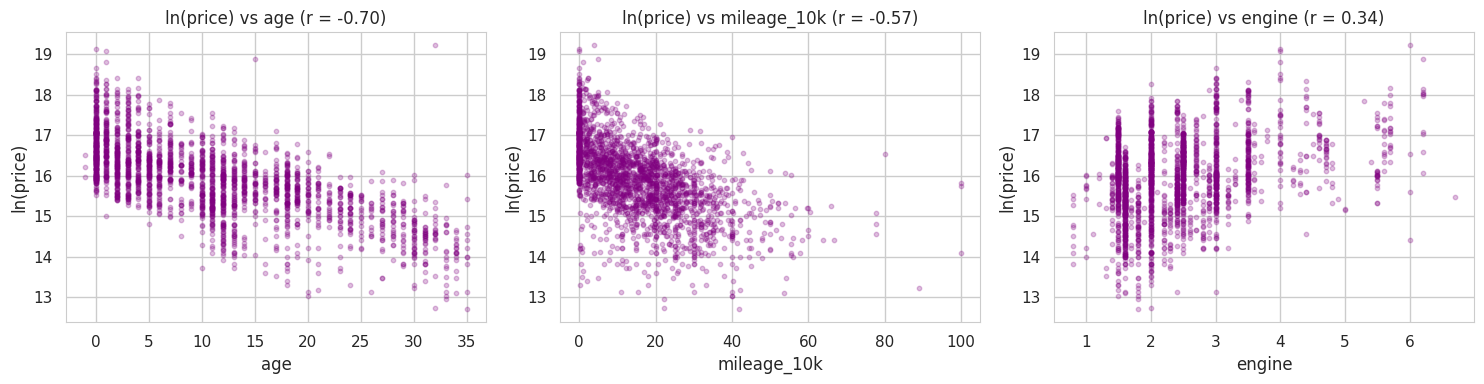

In [19]:
desc_tbl = analytical_df[['price', 'age', 'mileage_k', 'engine']].copy()
desc_tbl['price'] = desc_tbl['price'] / 1e6
desc_tbl.columns = ['Price, mln KZT', 'Age, years', 'Mileage, thous. km', 'Engine, L']
display(desc_tbl.describe().T.round(2))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['age', 'mileage_10k', 'engine']):
    ax.scatter(analytical_df[col], analytical_df['log_price'], alpha=0.25, s=10, color='purple')
    ax.set_xlabel(col)
    ax.set_ylabel('ln(price)')
    ax.set_title(f'ln(price) vs {col} (r = {analytical_df[col].corr(analytical_df.log_price):.2f})')
plt.tight_layout()
plt.show()

**Interpretation:**
- Price is strongly right-skewed: the mean (12.9 mln tenge) is much higher than the median (8.6 mln tenge), and the maximum is 222 mln tenge.
- The median car is 9 years old, has 123 thousand km of mileage and a 2.0 L engine. Age = -1 means a 2026 model-year car listed in 2025.
- ln(price) has a clear negative linear relation with age (r = -0.70), a weaker negative relation with mileage (r = -0.57) and a positive relation with engine volume (r = +0.34).

### 3.3. Basic analysis of categorical features

Categorical features are coded as 0/1 dummy variables. One category of each feature is the **reference group** (Korea for origin, petrol for fuel, manual for gearbox), otherwise the dummies would be perfectly collinear with the constant (dummy variable trap).


--- origin ---
        Count  Median price, mln KZT
origin                              
Japan     836                   9.50
Korea     477                   9.00
Europe    474                   6.65
China     358                  12.55
CIS       184                   3.50
USA       110                   5.60

--- body_type ---
               Count  Median price, mln KZT
body_type                                  
Other           1449                   6.15
Crossover/SUV    990                  13.50

--- transmission ---
              Count  Median price, mln KZT
transmission                              
automatic      1700                  10.00
manual          413                   2.75
cvt             205                   9.50
robot           121                  10.70

--- fuel_d ---
            Count  Median price, mln KZT
fuel_d                                  
petrol       2084                   8.38
hybrid        159                  18.50
lpg+petrol     89                

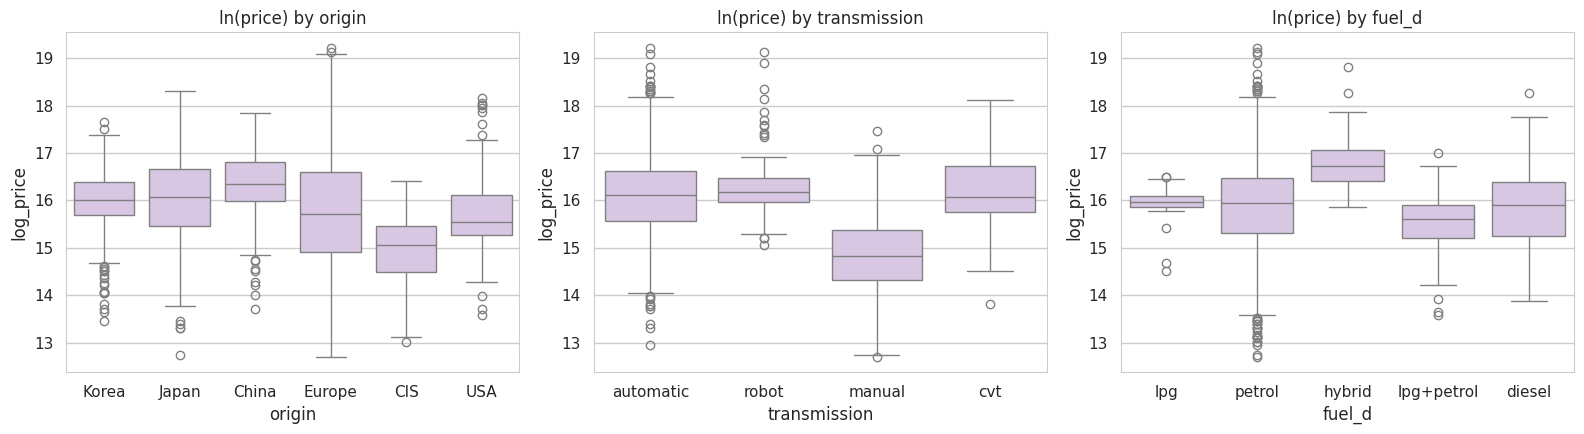

In [20]:
cat_df = analytical_df.copy()
cat_df['origin'] = 'Korea'
for col, name in {'origin_japan': 'Japan', 'origin_europe': 'Europe', 'origin_china': 'China',
                  'origin_cis': 'CIS', 'origin_usa': 'USA'}.items():
    cat_df.loc[cat_df[col] == 1, 'origin'] = name
cat_df['body_type'] = np.where(cat_df['is_suv'] == 1, 'Crossover/SUV', 'Other')

for col in ['origin', 'body_type', 'transmission', 'fuel_d']:
    summary = cat_df.groupby(col)['price'].agg(['count', 'median'])
    summary['median'] = (summary['median'] / 1e6).round(2)
    summary.columns = ['Count', 'Median price, mln KZT']
    print(f'\n--- {col} ---')
    print(summary.sort_values('Count', ascending=False))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, ['origin', 'transmission', 'fuel_d']):
    sns.boxplot(data=cat_df, x=col, y='log_price', ax=ax, color='#d9c2e8')
    ax.set_title(f'ln(price) by {col}')
plt.tight_layout()
plt.show()

**Interpretation:**
- All categories have enough observations to be used as dummy variables.
- CIS cars are the cheapest (median 3.5 mln tenge), and manual cars are much cheaper than automatic ones (2.75 vs 10 mln tenge). Crossovers/SUVs and hybrids are the most expensive groups.
- Automatic, CVT and robot gearboxes have similar prices, so they are combined into one dummy automatic.
- These are raw comparisons without controlling for other factors. For example, Chinese cars have the highest median only because most of them are new. In the multiple regression (Section 11) their effect becomes negative.

### 3.4. Train / test split

We split the data into a **training set (80%)** and a **test set (20%)**. Models are fitted on the training set, and the test set is used only to check prediction quality on new data (Sections 7.1, 12 and 13). Coefficients and hypothesis tests (Sections 5-11) are estimated on the full sample.

In [21]:
train_idx, test_idx = train_test_split(analytical_df.index, test_size=0.2, random_state=SEED)
print(f'Train: {len(train_idx)} cars, Test: {len(test_idx)} cars')
print(f"Mean ln(price): train = {analytical_df.loc[train_idx, 'log_price'].mean():.3f}, "
      f"test = {analytical_df.loc[test_idx, 'log_price'].mean():.3f}")

Train: 1951 cars, Test: 488 cars
Mean ln(price): train = 15.941, test = 15.925


## 4. Why we use the log of price

In a normal linear regression Y = b0 + b1 * X + e, a one-unit change in a predictor changes the price by a fixed amount b1 (in tenge).

But in the car market this does not work well for two reasons:

1. **Price falls in percentages, not fixed amounts**
Cars lose value as a percentage of their current price (for example, about 7% per year). A car that costs 30 million tenge and a car that costs 3 million tenge lose different amounts of money each year. The log of price lets the model work with percentage changes instead of absolute tenge amounts.

2. **Car prices are not symmetric**
Most cars have a low price (less than 50 mln), but a small number of expensive premium and luxury cars create a long right tail. Taking the log makes the distribution more balanced and closer to a normal curve. This helps the regression model to give more stable and reliable results.

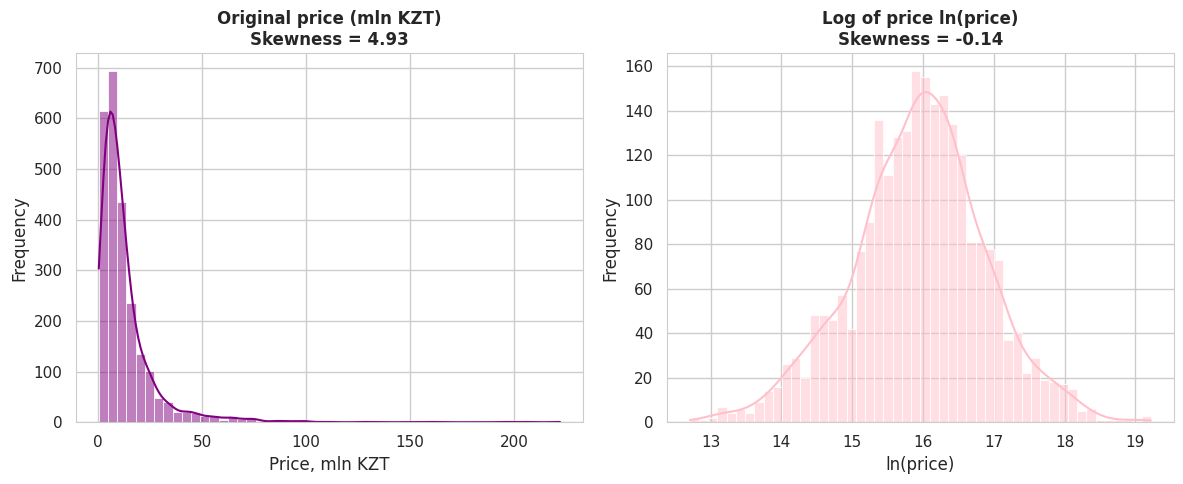

Skewness of prices in tenge: 4.93 (extremely strong right skew)
Skewness of ln(price):       -0.14 (almost symmetric distribution)


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Initial price
sns.histplot(analytical_df['price'] / 1e6, bins=50, kde=True, ax=axes[0], color='purple')
axes[0].set_title(f'Original price (mln KZT)\nSkewness = {stats.skew(analytical_df.price):.2f}', fontweight='bold')
axes[0].set_xlabel('Price, mln KZT')
axes[0].set_ylabel('Frequency')

# Log of price
sns.histplot(analytical_df['log_price'], bins=50, kde=True, ax=axes[1], color='pink')
axes[1].set_title(f'Log of price ln(price)\nSkewness = {stats.skew(analytical_df.log_price):.2f}', fontweight='bold')
axes[1].set_xlabel('ln(price)')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

print(f"Skewness of prices in tenge: {stats.skew(analytical_df.price):.2f} (extremely strong right skew)")
print(f"Skewness of ln(price):       {stats.skew(analytical_df.log_price):.2f} (almost symmetric distribution)")

## 5. Simple linear regression

Model: **ln(price) = b0 + b1 * age + e**

We use **age** because it has the strongest correlation with ln(price). OLS chooses b0 and b1 that minimize the sum of squared residuals. For one predictor the formulas are:

b1 = sum((x - mean(x)) * (y - mean(y)) / sum((x - mean(x))^2)

b0 = mean(y) - b1 * mean(x)

### 5.1. Estimation

By formulas: b0 = 16.6692, b1 = -0.0702


,coef,SE,t,p-value
const,16.6692,0.0205,812.7993,0.0
age,-0.0702,0.0015,-47.8758,0.0


R2 = 0.4847, Adjusted R2 = 0.4845


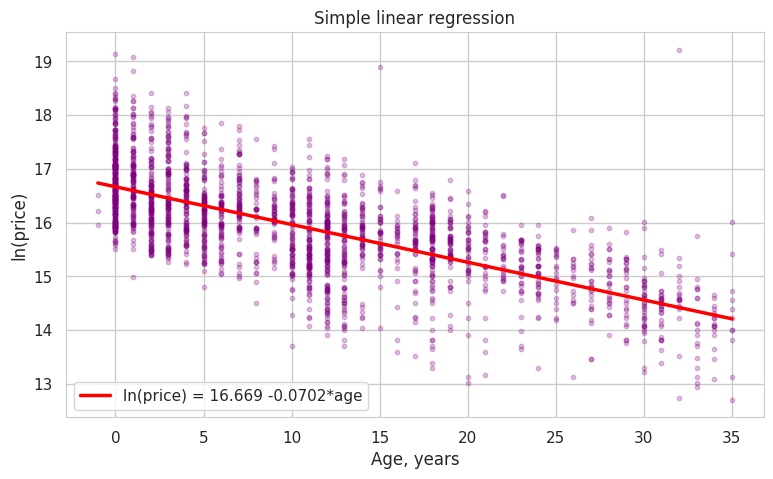

In [23]:
x = analytical_df['age']
y = analytical_df['log_price']

# OLS by formulas
b1 = ((x - x.mean()) * (y - y.mean())).sum() / ((x - x.mean()) ** 2).sum()
b0 = y.mean() - b1 * x.mean()
print(f'By formulas: b0 = {b0:.4f}, b1 = {b1:.4f}')

# the same with statsmodels
slr = sm.OLS(y, sm.add_constant(x)).fit()
display(pd.DataFrame({'coef': slr.params, 'SE': slr.bse, 't': slr.tvalues, 'p-value': slr.pvalues}).round(4))
print(f'R2 = {slr.rsquared:.4f}, Adjusted R2 = {slr.rsquared_adj:.4f}')

plt.figure(figsize=(9, 5))
plt.scatter(x, y, alpha=0.25, s=10, color='purple')
plt.plot(np.sort(x), b0 + b1 * np.sort(x), color='red', linewidth=2.5, label=f'ln(price) = {b0:.3f} {b1:+.4f}*age')
plt.xlabel('Age, years')
plt.ylabel('ln(price)')
plt.title('Simple linear regression')
plt.legend()
plt.show()

### 5.2. Hypothesis testing

- **H0:** b1 = 0 (age has no effect on price)
- **H1:** b1 is not equal to 0

t = b1 / SE(b1). We reject H0 at the 5% level if |t| > t_crit or p-value < 0.05.

In [24]:
t_stat = slr.params['age'] / slr.bse['age']
t_crit = stats.t.ppf(0.975, df=slr.df_resid)

print(f't = {t_stat:.2f}, t_crit = {t_crit:.3f}, p-value = {slr.pvalues["age"]:.2e}')
print('Reject H0' if abs(t_stat) > t_crit else 'Do not reject H0')

t = -47.88, t_crit = 1.961, p-value = 0.00e+00
Reject H0


**Interpretation:**
- **ln(price) = 16.669 - 0.0702 * age.** A new car (age 0) has a predicted price of e^16.669, approximately 17.4 mln tenge.
- Each extra year lowers the price by about **6.8%** (e^(-0.0702) - 1).
- |t| = 47.88 > t_crit = 1.961 and p-value < 0.05, so we **reject H0**: age has a significant effect on price.
- **R^2 = 0.485:** age alone explains 48.5% of the variation in ln(price). The other half is explained by other factors, so we move to multiple regression.

## 6. Correlation analysis and multicollinearity (VIF Analysis)

### 6.1. Pairwise correlation matrix
Before we put the features into the model, we build a correlation matrix for the numerical variables and the main binary regressors.

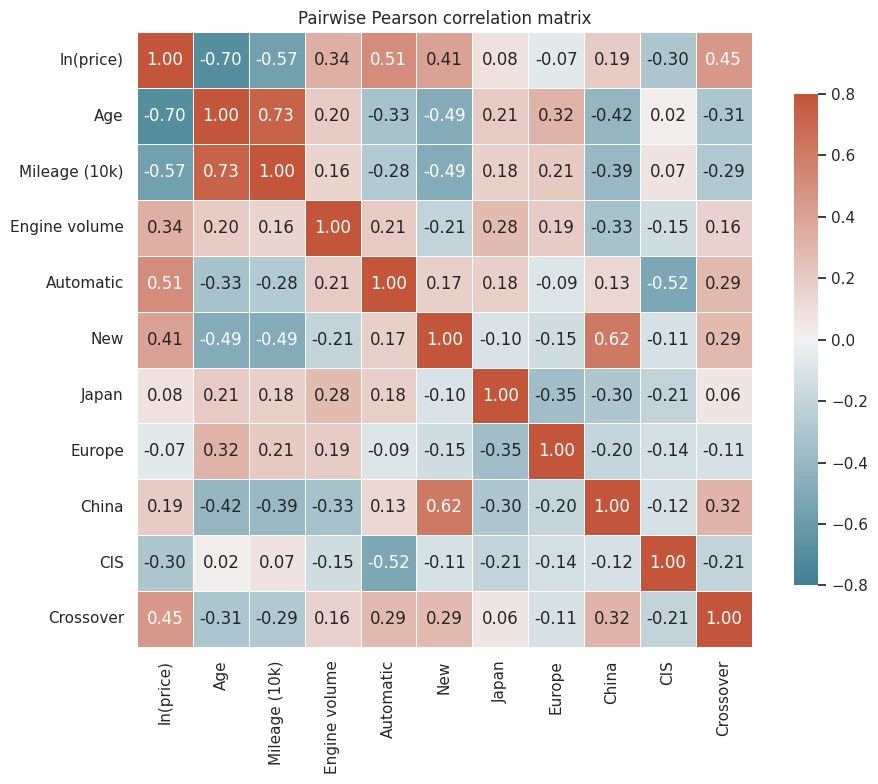

In [25]:
corr_vars = ['log_price', 'age', 'mileage_10k', 'engine', 'automatic', 'is_new',
             'origin_japan', 'origin_europe', 'origin_china', 'origin_cis', 'is_suv']

corr_labels = ['ln(price)', 'Age', 'Mileage (10k)', 'Engine volume', 'Automatic', 'New',
               'Japan', 'Europe', 'China', 'CIS', 'Crossover']

corr_matrix = analytical_df[corr_vars].corr()

plt.figure(figsize=(10, 8))

cmap = sns.diverging_palette(220, 20, as_cmap=True)

sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap=cmap, vmin=-0.8, vmax=0.8,
            square=True, linewidths=.5, xticklabels=corr_labels, yticklabels=corr_labels,
            cbar_kws={'shrink': .8})

plt.title('Pairwise Pearson correlation matrix')
plt.tight_layout()
plt.show()

### 6.2. Variance Inflation Factor (VIF)

General rule:
- VIF < 5 - low multicollinearity (safe zone)
- 5 <= VIF < 10 - moderate multicollinearity
- VIF >= 10 - critical multicollinearity

The candidate list contains age, mileage_10k and km_per_year. Since km_per_year = mileage / age, it does not carry new information and duplicates the other two variables, so we remove it.

In [26]:
def calc_vif_series(df_data, columns):
    X_mat = sm.add_constant(df_data[columns].astype(float))
    vif_vals = [variance_inflation_factor(X_mat.values, i) for i in range(1, X_mat.shape[1])]
    return pd.Series(vif_vals, index=columns).sort_values(ascending=False)

VARS_AFTER_VIF = [c for c in CANDIDATE_VARS if c != 'km_per_year']
vif_final_linear = calc_vif_series(analytical_df, VARS_AFTER_VIF)
display(vif_final_linear.round(2).to_frame('VIF'))

,VIF
age,2.99
origin_china,2.57
mileage_10k,2.28
origin_japan,2.25
is_new,2.11
origin_europe,2.05
automatic,1.89
origin_cis,1.77
hybrid,1.51
engine,1.46


All VIF values are below 5, so there is no serious multicollinearity in the model.

## 7. Multiple regression: building and comparing models

We compare models with:
- **R^2 and Adjusted R^2** (Adjusted R^2 has a penalty for the number of features)
- **AIC and BIC** - information criteria: lower is better; they balance fit and complexity (BIC has a stronger penalty)
- **5-Fold Cross-Validation RMSE** - prediction error on held-out data

### Hierarchy:
1. **M1 (Simple regression):** ln(price) = b0 + b1 * age
2. **M2:** + mileage (mileage_10k) and engine volume (engine)
3. **M3 (Full linear model):** all features after VIF
4. **M4:** M3 + centered age squared (age_c2) for the convex shape of depreciation + interaction age x Japan (age_x_japan) to test whether Japanese cars lose value more slowly
5. **M5 (Final model):** M4 without the two least significant features (highest p-values) - metallic and right_hand

In [27]:
analytical_df['age_c'] = analytical_df['age'] - analytical_df['age'].mean()
analytical_df['age_c2'] = analytical_df['age_c'] ** 2
analytical_df['age_x_japan'] = analytical_df['age_c'] * analytical_df['origin_japan']

M1_features = ['age']
M2_features = ['age', 'mileage_10k', 'engine']
M3_features = VARS_AFTER_VIF
M4_features = VARS_AFTER_VIF + ['age_c2', 'age_x_japan']

def fit_ols_model(feature_list, df_source=None):
    if df_source is None:
        df_source = analytical_df
    X_design = sm.add_constant(df_source[feature_list].astype(float))
    return sm.OLS(df_source['log_price'], X_design).fit()

# M5: remove the two features with the highest p-values in M4
m4_fit = fit_ols_model(M4_features)
print('Highest p-values in M4:')
print(m4_fit.pvalues.sort_values(ascending=False).head(3).round(4))

M5_features = [f for f in M4_features if f not in ['metallic', 'right_hand']]

MODELS_DICT = {
    'M1 (Simple: age)': M1_features,
    'M2 (age + mileage + engine)': M2_features,
    'M3 (Full linear after VIF)': M3_features,
    'M4 (M3 + age^2 + age x Japan)': M4_features,
    'M5 (Final: M4 - metallic, right_hand)': M5_features
}

def evaluate_cv_rmse(feature_list, k=5):
    X_vals = analytical_df[feature_list].astype(float).values
    y_vals = analytical_df['log_price'].values
    kf = KFold(n_splits=k, shuffle=True, random_state=SEED)
    fold_errors = []
    for train_i, test_i in kf.split(X_vals):
        estimator = LinearRegression().fit(X_vals[train_i], y_vals[train_i])
        y_hat = estimator.predict(X_vals[test_i])
        fold_errors.append(np.mean((y_vals[test_i] - y_hat) ** 2))
    return np.sqrt(np.mean(fold_errors))

comp_summary = []
for m_label, f_list in MODELS_DICT.items():
    fitted_ols = fit_ols_model(f_list)
    comp_summary.append({
        'Model': m_label,
        'k': len(f_list),
        'R2': round(fitted_ols.rsquared, 4),
        'Adj. R2': round(fitted_ols.rsquared_adj, 4),
        'AIC': round(fitted_ols.aic, 1),
        'BIC': round(fitted_ols.bic, 1),
        '5-Fold CV RMSE': round(evaluate_cv_rmse(f_list), 4)
    })

comparison_table = pd.DataFrame(comp_summary)
print('\n--- Comparison of models ---')
display(comparison_table)

Highest p-values in M4:
metallic      0.3784
right_hand    0.0494
on_order      0.0000
dtype: float64

--- Comparison of models ---


,Model,k,R2,Adj. R2,AIC,BIC,5-Fold CV RMSE
0,M1 (Simple: age),1,0.4847,0.4845,5011.5,5023.1,0.6758
1,M2 (age + mileage + engine),3,0.7303,0.7300,3436.1,3459.3,0.4901
2,M3 (Full linear after VIF),17,0.8271,0.8259,2380.0,2484.4,0.3948
3,M4 (M3 + age^2 + age x Japan),19,0.8312,0.8299,2325.2,2441.2,0.3907
4,"M5 (Final: M4 - metallic, right_hand)",17,0.8309,0.8297,2325.8,2430.2,0.3907


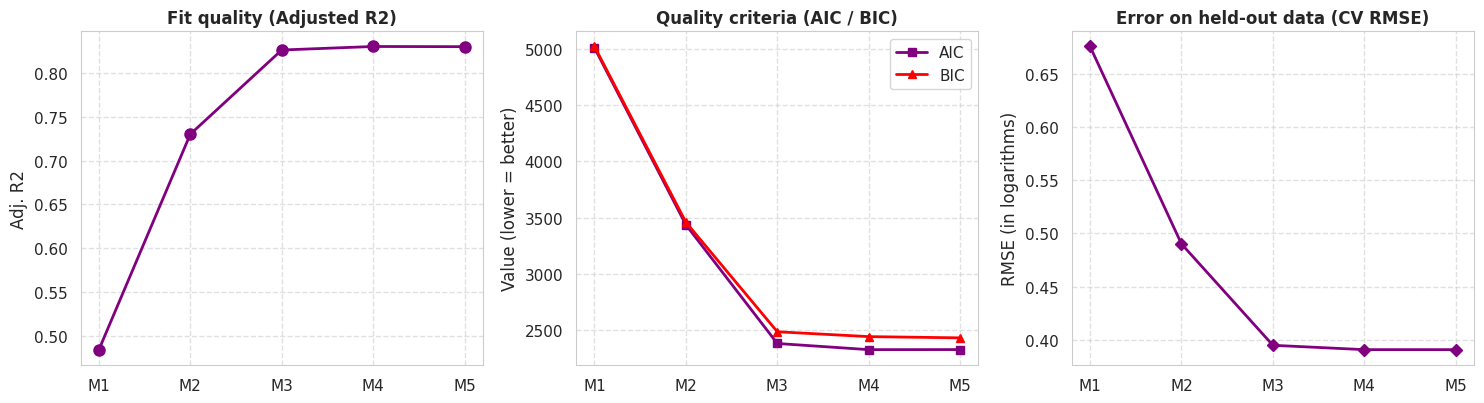

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
short_names = ['M1', 'M2', 'M3', 'M4', 'M5']

axes[0].plot(short_names, comparison_table['Adj. R2'], marker='o', color='purple', linewidth=2, markersize=8)
axes[0].set_title('Fit quality (Adjusted R2)', fontweight='bold')
axes[0].set_ylabel('Adj. R2')

axes[1].plot(short_names, comparison_table['AIC'], marker='s', color='purple', linewidth=2, label='AIC')
axes[1].plot(short_names, comparison_table['BIC'], marker='^', color='red', linewidth=2, label='BIC')
axes[1].set_title('Quality criteria (AIC / BIC)', fontweight='bold')
axes[1].set_ylabel('Value (lower = better)')
axes[1].legend()

axes[2].plot(short_names, comparison_table['5-Fold CV RMSE'], marker='D', color='purple', linewidth=2)
axes[2].set_title('Error on held-out data (CV RMSE)', fontweight='bold')
axes[2].set_ylabel('RMSE (in logarithms)')

for ax in axes:
    ax.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

**Interpretation:**
- Adding mileage and engine (M2) raises Adjusted R^2 from 0.48 to 0.73, and adding all other features (M3) raises it to 0.83.
- M4 (age^2 and age x Japan) has lower AIC and BIC than M3, so the non-linear terms improve the model.
- In M4, metallic (p = 0.38) and right_hand (p = 0.049) are the weakest features. Removing them (M5) gives the **lowest BIC** (2430.2), almost the same Adjusted R^2 and the same CV RMSE. M5 is the final model.

### 7.1. Evaluation on the test set

Each model is fitted on the training set and its error is measured on the test set. If the test error is much larger than the train error, the model is overfitted.

In [29]:
rows = []
y_train = analytical_df.loc[train_idx, 'log_price']
y_test = analytical_df.loc[test_idx, 'log_price']
for m_label, f_list in MODELS_DICT.items():
    m = fit_ols_model(f_list, df_source=analytical_df.loc[train_idx])
    pred_train = m.predict(sm.add_constant(analytical_df.loc[train_idx, f_list].astype(float)))
    pred_test = m.predict(sm.add_constant(analytical_df.loc[test_idx, f_list].astype(float)))
    rows.append({
        'Model': m_label,
        'RMSE train': np.sqrt(np.mean((y_train - pred_train) ** 2)),
        'RMSE test': np.sqrt(np.mean((y_test - pred_test) ** 2)),
        'R2 test': 1 - np.sum((y_test - pred_test) ** 2) / np.sum((y_test - y_test.mean()) ** 2)
    })
display(pd.DataFrame(rows).round(4))

,Model,RMSE train,RMSE test,R2 test
0,M1 (Simple: age),0.6732,0.6847,0.4903
1,M2 (age + mileage + engine),0.4834,0.5106,0.7166
2,M3 (Full linear after VIF),0.3903,0.3969,0.8288
3,M4 (M3 + age^2 + age x Japan),0.3854,0.3935,0.8317
4,"M5 (Final: M4 - metallic, right_hand)",0.3856,0.3944,0.8309


**Interpretation:** For all models the train and test errors are very close, so there is **no overfitting**. The final model M5 has R^2 = 0.831 on the test set, the same as on the full sample.

## 8. Final model specification (M5) and parameter estimates

The final model **M5** has the lowest BIC (2430.2) and the same cross-validation error as M4 (CV RMSE = 0.3907) with two features less. It removes the two insignificant features metallic and right_hand.

In [30]:
final_ols = fit_ols_model(M5_features)
print(final_ols.summary())

                            OLS Regression Results                            
Dep. Variable:              log_price   R-squared:                       0.831
Model:                            OLS   Adj. R-squared:                  0.830
Method:                 Least Squares   F-statistic:                     699.7
Date:                Tue, 27 Oct 2026   Prob (F-statistic):               0.00
Time:                        12:06:33   Log-Likelihood:                -1144.9
No. Observations:                2439   AIC:                             2326.
Df Residuals:                    2421   BIC:                             2430.
Df Model:                          17                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const            15.5280      0.039    394.673

## 9. Checking the classical OLS assumptions

1. **Homoscedasticity:** Breusch-Pagan test. H0: the variance of the errors is constant.
2. **Autocorrelation:** Durbin-Watson statistic. A value close to 2 means no autocorrelation of the residuals.
3. **Residual plots:** "Residuals vs Fitted" (linearity, constant variance) and Normal Q-Q plot (shape of the residual distribution).

In [31]:
fitted_vals = final_ols.fittedvalues
residuals = final_ols.resid

bp_stat, bp_pval, bp_f, bp_fpval = het_breuschpagan(residuals, final_ols.model.exog)
dw_value = durbin_watson(residuals)

diag_results = pd.DataFrame([
    {'Test': 'Breusch-Pagan', 'Statistic': f'LM = {bp_stat:.2f}', 'p-value': f'{bp_pval:.2e}'},
    {'Test': 'Durbin-Watson', 'Statistic': f'DW = {dw_value:.3f}', 'p-value': '-'}
])
display(diag_results)

,Test,Statistic,p-value
0,Breusch-Pagan,LM = 232.11,9.20e-40
1,Durbin-Watson,DW = 1.975,-


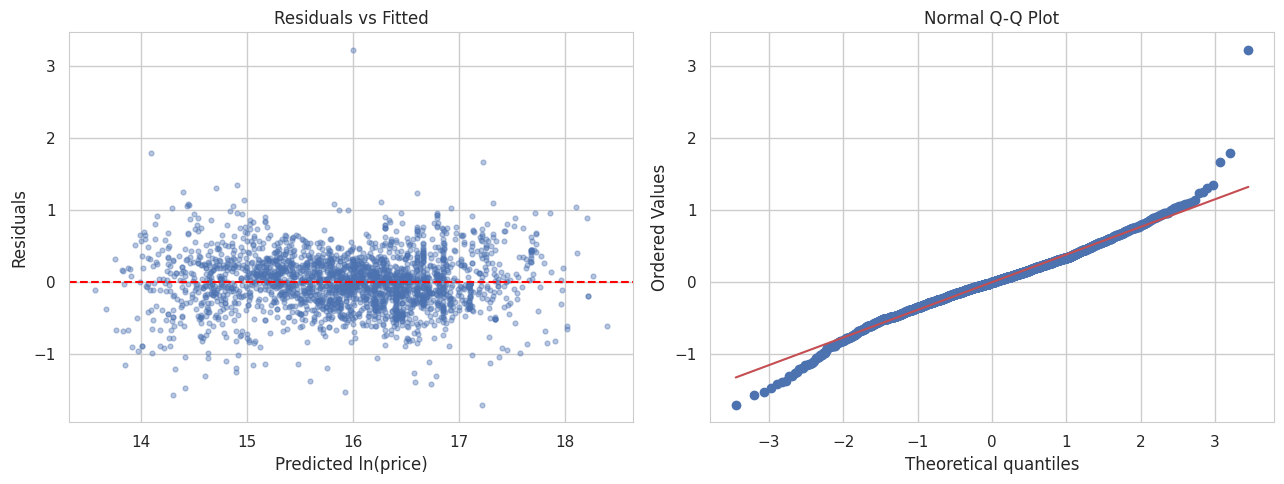

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(fitted_vals, residuals, alpha=0.4, s=12)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_title('Residuals vs Fitted')
axes[0].set_xlabel('Predicted ln(price)')
axes[0].set_ylabel('Residuals')

stats.probplot(residuals, dist='norm', plot=axes[1])
axes[1].set_title('Normal Q-Q Plot')

plt.tight_layout()
plt.show()

**Interpretation:**
- **Breusch-Pagan:** p-value = 9.2 * 10^(-40) < 0.05, so we reject H0. There is **heteroscedasticity**: the error variance is not constant. The OLS coefficients are still unbiased, but the standard errors may be inaccurate. Almost all |t| values in the model are greater than 4, so the conclusions about significance hold anyway. We note this as a limitation.
- **Durbin-Watson = 1.975, close to 2:** no autocorrelation of residuals (as expected for cross-sectional data).
- **Residuals vs Fitted:** the residuals are spread around zero without a clear pattern, so the linear form is reasonable.
- **Q-Q plot:** the middle of the distribution lies on the line, but the tails deviate. There are more extreme residuals than in a normal distribution (very over- or under-priced ads).

## 10. Influential observations: Leverage and Cook's Distance

Influential observations can distort regression coefficients. We check the sample using two econometric metrics:

1. **Leverage (hat-matrix diagonal h_ii):** measures how far a feature vector X_i is from the center of the sample.
2. **Cook's Distance (D_i):** estimates the total shift in all predicted values when removing the i-th observation.

Cook's distance threshold 4/n = 0.00164 | Observations above threshold: 189
Max Cook's distance = 0.0779 (well below the critical level 1.0)
Leverage threshold 2p/n = 0.01476 | High leverage observations: 200


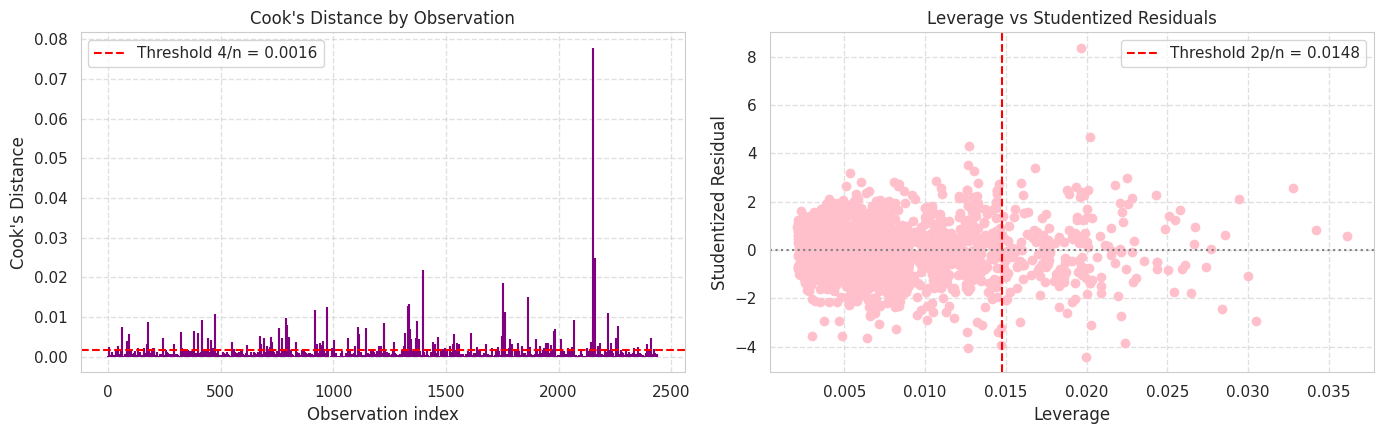

Top 5 cars with the highest influence on model parameters:


,name,year,price,mileage_10k,engine,cooks_d,leverage
2152,Mercedes-Benz S 600,1993,222000000,3.8400,6.0,0.077908,0.019638
2164,Jeep Wrangler,1995,8000000,16.8000,2.5,0.025015,0.020219
1399,Nissan Elgrand,2024,5500000,28.0000,3.5,0.021999,0.019944
1753,Volkswagen Golf,1992,420000,22.2855,1.8,0.018689,0.022368
1866,Mitsubishi L200 DC Invite,2025,10450000,0.0000,2.4,0.015128,0.030465


In [33]:
influence_obj = final_ols.get_influence()
cook_distances = influence_obj.cooks_distance[0]
leverage_values = influence_obj.hat_matrix_diag
n_sample = len(analytical_df)
p_params = len(final_ols.params)

cook_cutoff = 4.0 / n_sample
lev_cutoff = 2.0 * p_params / n_sample

analytical_df['cooks_d'] = cook_distances
analytical_df['leverage'] = leverage_values

print(f"Cook's distance threshold 4/n = {cook_cutoff:.5f} | Observations above threshold: {(cook_distances > cook_cutoff).sum()}")
print(f"Max Cook's distance = {cook_distances.max():.4f} (well below the critical level 1.0)")
print(f"Leverage threshold 2p/n = {lev_cutoff:.5f} | High leverage observations: {(leverage_values > lev_cutoff).sum()}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Cook's distance plot
axes[0].stem(np.arange(n_sample), cook_distances, linefmt = 'purple', markerfmt=' ', basefmt=' ')
axes[0].axhline(cook_cutoff, color='red', linestyle='--', label=f'Threshold 4/n = {cook_cutoff:.4f}')
axes[0].set_title("Cook's Distance by Observation")
axes[0].set_xlabel("Observation index")
axes[0].set_ylabel("Cook's Distance")
axes[0].legend()

# Leverage vs Studentized Residuals
axes[1].scatter(leverage_values, influence_obj.resid_studentized_internal, color='pink')
axes[1].axvline(lev_cutoff, color='red', linestyle='--', label=f'Threshold 2p/n = {lev_cutoff:.4f}')
axes[1].axhline(0, color='gray', linestyle=':')
axes[1].set_title("Leverage vs Studentized Residuals")
axes[1].set_xlabel("Leverage")
axes[1].set_ylabel("Studentized Residual")
axes[1].legend()

for ax in axes:
    ax.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

# Top 5 observations with the highest Cook's distance
top_cook = analytical_df.sort_values('cooks_d', ascending=False)[['name', 'year', 'price', 'mileage_10k', 'engine', 'cooks_d', 'leverage']].head(5)
print("Top 5 cars with the highest influence on model parameters:")
display(top_cook)

### 10.1. Checking the model after removing influential points
We estime the final model the second time, after removing all observations with D_i > 4/n and compare the stability of the coefficient signs and values.

In [34]:
clean_mask = analytical_df['cooks_d'] <= cook_cutoff
model_refit = fit_ols_model(M5_features, df_source=analytical_df[clean_mask])

robustness_check = pd.DataFrame({
    'Full sample (n = 2439)': final_ols.params,
    f'Without outliers (n = {clean_mask.sum()})': model_refit.params,
    'Estimate change, %': (model_refit.params / final_ols.params - 1) * 100,
    'Sign preserved?': np.sign(final_ols.params) == np.sign(model_refit.params),
    'p-value (no outliers)': model_refit.pvalues
})

print(f"R^2 increased from {final_ols.rsquared:.4f} to {model_refit.rsquared:.4f}")
display(robustness_check.round(4))

R^2 increased from 0.8309 to 0.8791


,Full sample (n = 2439),Without outliers (n = 2250),"Estimate change, %",Sign preserved?,p-value (no outliers)
const,15.5280,15.5375,0.0613,True,0.0000
age,-0.0832,-0.0802,-3.5774,True,0.0000
mileage_10k,-0.0054,-0.0060,9.8323,True,0.0000
engine,0.3837,0.3856,0.4833,True,0.0000
automatic,0.1622,0.1523,-6.1155,True,0.0000
is_new,0.2032,0.1891,-6.9478,True,0.0000
origin_japan,0.2853,0.2914,2.1513,True,0.0000
origin_europe,0.4180,0.3837,-8.2064,True,0.0000
origin_china,-0.3243,-0.3580,10.4029,True,0.0000
origin_cis,-0.3553,-0.4216,18.6700,True,0.0000


**Interpretation:** 189 observations are above the threshold 4/n, but the maximum Cook's distance is only 0.078, much lower than 1, so no single car dominates the model. After removing the influential points, **all coefficients keep their sign** and stay significant, and R^2 rises from 0.831 to 0.879. The results are stable.

## 11. Economic interpretation of results

The dependent variable is ln(price), so the effect of a feature in percent is:

Effect (%) = (e^b - 1) * 100%

For small coefficients the effect is roughly b * 100%. Below is the summary table with OLS standard errors and 95% confidence intervals.

In [35]:
conf_int_df = final_ols.conf_int()

PARAM_LABELS = {
    'const': 'Constant (baseline)',
    'age': 'Car age (years)',
    'mileage_10k': 'Mileage (+10000 km)',
    'engine': 'Engine size (+1.0 L)',
    'automatic': 'Automatic (automatic/robotic/CVT)',
    'is_new': 'New car from a dealer',
    'origin_japan': 'Japan',
    'origin_europe': 'Europe',
    'origin_china': 'China',
    'origin_cis': 'CIS',
    'origin_usa': 'USA',
    'is_suv': 'Body type: crossover / SUV',
    'diesel': 'Diesel engine',
    'hybrid': 'Hybrid engine',
    'gas': 'Gas / Gas-petrol',
    'on_order': 'On order',
    'age_c2': 'Age squared',
    'age_x_japan': 'Age x Japan'
}

interpretation_list = []
for param_name in final_ols.params.index:
    beta = final_ols.params[param_name]
    p_val = final_ols.pvalues[param_name]
    no_pct = param_name in ['const', 'age_c2', 'age_x_japan']
    interpretation_list.append({
        'Pricing factor': PARAM_LABELS[param_name],
        'Coefficient b': round(beta, 4),
        'SE': round(final_ols.bse[param_name], 4),
        't-statistic': round(final_ols.tvalues[param_name], 2),
        'p-value': '< 0.0001' if p_val < 0.0001 else f'{p_val:.4f}',
        'Effect on price (%)': '-' if no_pct else f'{(np.exp(beta) - 1) * 100:+.1f}%',
        '95% CI': '-' if no_pct else f'[{(np.exp(conf_int_df.loc[param_name, 0]) - 1) * 100:+.1f}%; {(np.exp(conf_int_df.loc[param_name, 1]) - 1) * 100:+.1f}%]'
    })

final_interpretation_table = pd.DataFrame(interpretation_list)
display(final_interpretation_table)

,Pricing factor,Coefficient b,SE,t-statistic,p-value,Effect on price (%),95% CI
0,Constant (baseline),15.5280,0.0393,394.67,< 0.0001,-,-
1,Car age (years),-0.0832,0.0022,-37.86,< 0.0001,-8.0%,[-8.4%; -7.6%]
2,Mileage (+10000 km),-0.0054,0.0009,-5.90,< 0.0001,-0.5%,[-0.7%; -0.4%]
3,Engine size (+1.0 L),0.3837,0.0102,37.71,< 0.0001,+46.8%,[+43.9%; +49.7%]
4,Automatic (automatic/robotic/CVT),0.1622,0.0290,5.60,< 0.0001,+17.6%,[+11.1%; +24.5%]
5,New car from a dealer,0.2032,0.0332,6.13,< 0.0001,+22.5%,[+14.8%; +30.8%]
6,Japan,0.2853,0.0247,11.56,< 0.0001,+33.0%,[+26.7%; +39.6%]
7,Europe,0.4180,0.0296,14.14,< 0.0001,+51.9%,[+43.3%; +61.0%]
8,China,-0.3243,0.0362,-8.95,< 0.0001,-27.7%,[-32.7%; -22.4%]
9,CIS,-0.3553,0.0402,-8.83,< 0.0001,-29.9%,[-35.2%; -24.1%]


### 11.1. Answers to the Research Questions

#### 1. Depreciation rate:

- **Age:** For non-Japanese cars, each extra year lowers the price by **-8.0% per year** (b = -0.0832, p < 0.0001). The squared age variable age_c^2 is positive (b = +0.0006, p < 0.0001). This means the price drops fastest in the first 3 to 5 years, and then the value loss slows down over time.
- **Mileage:** Every extra **10,000 km** lowers the price by about **-0.54%** (b = -0.0054, p < 0.0001). That is about -5.3% for every 100,000 km. Car age has a much bigger impact on price than mileage alone.

#### 2. "Japan Premium":

- Japanese cars have a clear extra value over Korean brands (Hyundai/Kia, the reference group) of **+33.0%** (b = +0.2853, p = 4.2 * 10^-30), when comparing cars with the same age, mileage, and engine size.
- Compared to Chinese cars, Japanese cars cost about **+84.0%** more (e^(0.2853+0.3243) - 1). Compared to CIS cars (VAZ/Lada), they cost about **+89.8%** more (e^(0.2853+0.3553) - 1).
- **Slower aging:** The interaction between age and Japanese origin is positive and significant (b = +0.0108, p = 1.7 * 10^-7). The yearly price loss for Japanese cars is -0.0832 + 0.0108 = -0.0724 (**-7.0% per year** vs. -8.0% for other brands). Japanese cars lose value more slowly, which proves they hold their value better over time.

#### 3. Effect of options:

- **Automatic transmission:** An automatic gearbox increases the price by about **+17.6%** (b = +0.1622, p < 0.0001), all else being equal.
- **SUV body:** Crossovers and SUVs cost **+22.3%** more than sedans and hatchbacks with the same engine and age.
- **Hybrid and diesel:** Diesel engines add **+23.4%** to the price, and hybrids add **+28.7%**.

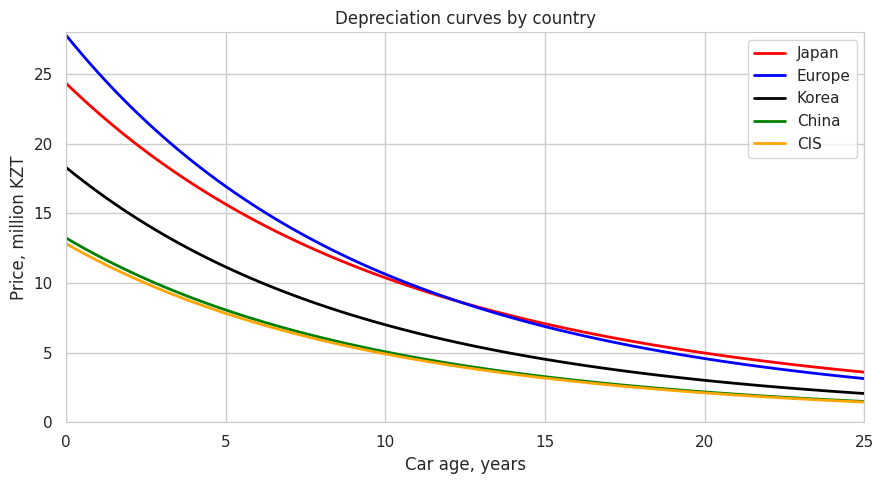

In [36]:
plt.figure(figsize=(9, 5))
ages = np.linspace(0, 25, 100)
ages_c = ages - analytical_df['age'].mean()

b = final_ols.params
base = b['const'] + b['engine'] * 2.0 + b['automatic'] + b['is_suv']

curves = [
    ('Japan', b['origin_japan'], b['age_x_japan'], 'red'),
    ('Europe', b['origin_europe'], 0, 'blue'),
    ('Korea', 0, 0, 'black'),
    ('China', b['origin_china'], 0, 'green'),
    ('CIS', b['origin_cis'], 0, 'orange')
]

for label, b_country, b_inter, col in curves:
    log_p = base + b_country + (b['age'] + b_inter) * ages + b['mileage_10k'] * (1.2 * ages) + b['age_c2'] * (ages_c ** 2)
    plt.plot(ages, np.exp(log_p) / 1e6, label=label, color=col, linewidth=2)

plt.title("Depreciation curves by country")
plt.xlabel("Car age, years")
plt.ylabel("Price, million KZT")
plt.xlim(0, 25)
plt.ylim(0, 28)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## 12. Logistic regression: premium segment

The dependent variable is binary: premium = 1 if the price is in the top 25% (at or above the 75th percentile of training prices), otherwise 0.

A linear model can predict probabilities below 0 or above 1. Logistic regression models the **log-odds (logit)** instead:

ln(p / (1 - p)) = b0 + b1 * x1 + ... + bk * xk

p = 1 / (1 + e^(-z)), where z = b0 + b1 * x1 + ... + bk * xk

- **b (logit coefficient):** change in the log-odds when x increases by 1.
- **Odds Ratio = e^b:** how many times the odds p / (1 - p) change when x increases by 1. If OR > 1 the odds rise, if OR < 1 the odds fall.

The model is fitted on the training set and evaluated on the test set.

In [37]:
premium_threshold = analytical_df.loc[train_idx, 'price'].quantile(0.75)
analytical_df['premium'] = (analytical_df['price'] >= premium_threshold).astype(int)
print(f'Premium threshold: {premium_threshold / 1e6:.2f} mln KZT')
print('Number of premium CIS cars:', analytical_df.loc[analytical_df.origin_cis == 1, 'premium'].sum())

Premium threshold: 14.90 mln KZT
Number of premium CIS cars: 0


There are **no premium CIS cars**, so the coefficient of origin_cis cannot be estimated (it goes to minus infinity). We leave it out: CIS cars are in the reference group together with Korean cars.

In [38]:
LOGIT_FEATURES = ['age', 'mileage_10k', 'engine', 'automatic', 'is_new',
                  'origin_japan', 'origin_europe', 'origin_china', 'origin_usa',
                  'is_suv', 'diesel', 'hybrid', 'gas', 'on_order']

X_train_logit = sm.add_constant(analytical_df.loc[train_idx, LOGIT_FEATURES].astype(float))
X_test_logit = sm.add_constant(analytical_df.loc[test_idx, LOGIT_FEATURES].astype(float))
y_train_logit = analytical_df.loc[train_idx, 'premium']
y_test_logit = analytical_df.loc[test_idx, 'premium']

logit_model = sm.Logit(y_train_logit, X_train_logit).fit(disp=0)

logit_table = pd.DataFrame({
    'Logit coef': logit_model.params,
    'p-value': logit_model.pvalues,
    'Odds Ratio': np.exp(logit_model.params)
})
display(logit_table.round(4))

,Logit coef,p-value,Odds Ratio
const,-5.7395,0.0000,0.0032
age,-0.5759,0.0000,0.5622
mileage_10k,-0.0388,0.0444,0.9619
engine,2.4391,0.0000,11.4624
automatic,0.1416,0.8057,1.1521
is_new,0.2304,0.4668,1.2591
origin_japan,2.2717,0.0000,9.6962
origin_europe,3.2103,0.0000,24.7858
origin_china,-0.7411,0.0392,0.4766
origin_usa,-0.3326,0.6295,0.7170


**Interpretation of Odds Ratios** (reference group: Korean/CIS cars):
- **Age:** OR = 0.56. Each extra year multiplies the odds of being premium by 0.56 (-44%).
- **Engine:** OR = 11.5. Each extra litre multiplies the odds by 11.5.
- **Europe:** OR = 24.8 and **Japan:** OR = 9.7. These cars have much higher odds of being premium. **China:** OR = 0.48 (lower odds).
- **Crossover/SUV:** OR = 4.0, **hybrid:** OR = 4.1, **diesel:** OR = 3.9.
- automatic, is_new, origin_usa and gas are not significant (p > 0.05).

### 12.1. Confusion Matrix, Accuracy, Precision, Recall, F1

A car is classified as premium if the predicted probability is 0.5 or higher.

- **Accuracy** = (TP + TN) / n - share of correct answers
- **Precision** = TP / (TP + FP) - of cars predicted as premium, how many are really premium
- **Recall** = TP / (TP + FN) - of real premium cars, how many the model found
- **F1** = 2 * Precision * Recall / (Precision + Recall)

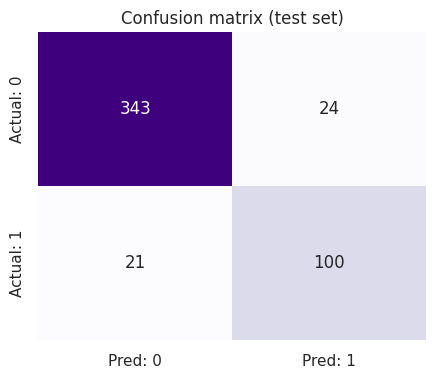

Accuracy  = 0.9078
Precision = 0.8065
Recall    = 0.8264
F1-score  = 0.8163


In [39]:
p_test = logit_model.predict(X_test_logit)
pred_test = (p_test >= 0.5).astype(int)

cm = confusion_matrix(y_test_logit, pred_test)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples', cbar=False,
            xticklabels=['Pred: 0', 'Pred: 1'], yticklabels=['Actual: 0', 'Actual: 1'])
plt.title('Confusion matrix (test set)')
plt.show()

print(f'Accuracy  = {accuracy_score(y_test_logit, pred_test):.4f}')
print(f'Precision = {precision_score(y_test_logit, pred_test):.4f}')
print(f'Recall    = {recall_score(y_test_logit, pred_test):.4f}')
print(f'F1-score  = {f1_score(y_test_logit, pred_test):.4f}')

### 12.2. ROC curve and AUC

The ROC curve shows the True Positive Rate against the False Positive Rate for all cutoffs. **AUC** = area under the curve: 0.5 = random guessing, 1.0 = perfect classifier.

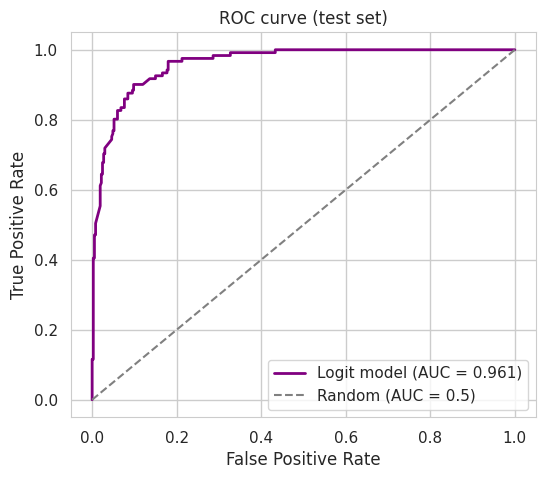

In [40]:
fpr, tpr, _ = roc_curve(y_test_logit, p_test)
auc_value = roc_auc_score(y_test_logit, p_test)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='purple', linewidth=2, label=f'Logit model (AUC = {auc_value:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random (AUC = 0.5)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC curve (test set)')
plt.legend()
plt.show()

**Interpretation:**
- **Accuracy = 90.8%.** If the model always said "not premium", accuracy would be only about 75%, so the model is much better than guessing.
- **Precision = 0.81:** 81% of the cars predicted as premium are really premium.
- **Recall = 0.83:** the model found 83% of all premium cars.
- **F1 = 0.82** and **AUC = 0.96**: the model separates premium and non-premium cars very well.

## 13. Regularization and overfitting

### 13.1. Overfitting and the bias-variance tradeoff

- A **too simple** model has high **bias** (underfitting).
- A **too complex** model has high **variance**: it learns the noise of the training data (overfitting). The training error is small, but the error on new data is large.

Example: we take only 30 training cars and fit polynomials of age with degree 1 to 12.

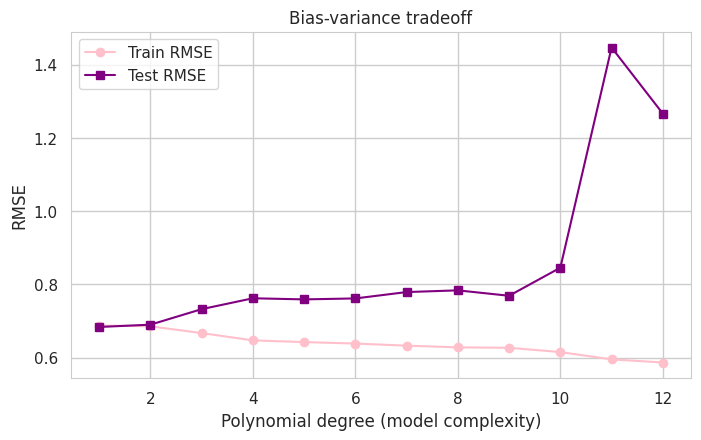

In [41]:
small_idx = np.random.RandomState(SEED).choice(train_idx, 30, replace=False)
x_small = analytical_df.loc[small_idx, 'age'].values
y_small = analytical_df.loc[small_idx, 'log_price'].values
x_mean, x_std = x_small.mean(), x_small.std()
x_test_age = analytical_df.loc[test_idx, 'age'].values
y_test_age = analytical_df.loc[test_idx, 'log_price'].values

degrees = range(1, 13)
train_err, test_err = [], []
for d in degrees:
    coefs = np.polyfit((x_small - x_mean) / x_std, y_small, d)
    train_err.append(np.sqrt(np.mean((np.polyval(coefs, (x_small - x_mean) / x_std) - y_small) ** 2)))
    test_err.append(np.sqrt(np.mean((np.polyval(coefs, (x_test_age - x_mean) / x_std) - y_test_age) ** 2)))

plt.figure(figsize=(8, 4.5))
plt.plot(degrees, train_err, marker='o', color='pink', label='Train RMSE')
plt.plot(degrees, test_err, marker='s', color='purple', label='Test RMSE')
plt.xlabel('Polynomial degree (model complexity)')
plt.ylabel('RMSE')
plt.title('Bias-variance tradeoff')
plt.legend()
plt.show()

### 13.2. Ridge (L2) and Lasso (L1)

- **Ridge:** minimizes the sum of squared residuals + alpha * sum(b^2). It shrinks coefficients towards zero and helps under multicollinearity.
- **Lasso:** minimizes the sum of squared residuals + alpha * sum(|b|). It can set coefficients **exactly to zero** (feature selection).

alpha = 0 gives OLS, a larger alpha gives a stronger penalty. Features are standardized first, because the penalty depends on their scale. alpha is chosen by **5-fold cross-validation** on the training set (RidgeCV, LassoCV). We use all 19 features of model M4.

In [42]:
X_train_reg = analytical_df.loc[train_idx, M4_features].astype(float)
X_test_reg = analytical_df.loc[test_idx, M4_features].astype(float)
y_train_reg = analytical_df.loc[train_idx, 'log_price']
y_test_reg = analytical_df.loc[test_idx, 'log_price']

scaler = StandardScaler().fit(X_train_reg)
X_train_s = scaler.transform(X_train_reg)
X_test_s = scaler.transform(X_test_reg)

ols_reg = LinearRegression().fit(X_train_s, y_train_reg)
ridge = RidgeCV(alphas=np.logspace(-3, 3, 50), cv=5).fit(X_train_s, y_train_reg)
lasso = LassoCV(cv=5, random_state=SEED, max_iter=10000).fit(X_train_s, y_train_reg)
print(f'Best alpha: Ridge = {ridge.alpha_:.4f}, Lasso = {lasso.alpha_:.5f}')

def rmse(model):
    return np.sqrt(np.mean((y_test_reg - model.predict(X_test_s)) ** 2))

results = pd.DataFrame({
    'RMSE test': [rmse(ols_reg), rmse(ridge), rmse(lasso)],
    'Non-zero coefficients': [np.sum(ols_reg.coef_ != 0), np.sum(ridge.coef_ != 0), np.sum(lasso.coef_ != 0)]
}, index=['OLS', 'Ridge', 'Lasso'])
display(results.round(4))

coefs = pd.DataFrame({'OLS': ols_reg.coef_, 'Ridge': ridge.coef_, 'Lasso': lasso.coef_}, index=M4_features)
display(coefs.round(4))

Best alpha: Ridge = 3.5565, Lasso = 0.00070


,RMSE test,Non-zero coefficients
OLS,0.3935,19
Ridge,0.3936,19
Lasso,0.3935,19


,OLS,Ridge,Lasso
age,-0.7734,-0.7631,-0.7665
mileage_10k,-0.0752,-0.0779,-0.0756
engine,0.3649,0.3637,0.3646
automatic,0.0644,0.0654,0.0642
is_new,0.0753,0.0767,0.0752
origin_japan,0.1275,0.1262,0.1262
origin_europe,0.1578,0.1558,0.1556
origin_china,-0.1268,-0.1258,-0.1239
origin_cis,-0.0857,-0.0860,-0.0858
origin_usa,-0.0511,-0.0510,-0.0504


### 13.3. How Lasso sets coefficients to zero

To see the feature selection of Lasso, we fit it with several larger values of alpha.

In [43]:
lasso_rows = []
for a in [0.001, 0.01, 0.05, 0.1, 0.3]:
    m = Lasso(alpha=a, max_iter=10000).fit(X_train_s, y_train_reg)
    lasso_rows.append({
        'alpha': a,
        'Non-zero coefficients': np.sum(m.coef_ != 0),
        'RMSE test': round(np.sqrt(np.mean((y_test_reg - m.predict(X_test_s)) ** 2)), 4),
        'Features set to zero': ', '.join(np.array(M4_features)[m.coef_ == 0])
    })
pd.set_option('display.max_colwidth', None)
display(pd.DataFrame(lasso_rows))

,alpha,Non-zero coefficients,RMSE test,Features set to zero
0,0.001,19,0.3936,
1,0.010,17,0.3982,"metallic, right_hand"
2,0.050,11,0.4410,"origin_china, diesel, gas, metallic, right_hand, on_order, age_c2, age_x_japan"
3,0.100,7,0.4933,"origin_japan, origin_europe, origin_china, origin_usa, diesel, hybrid, gas, metallic, right_hand, on_order, age_c2, age_x_japan"
4,0.300,3,0.7031,"mileage_10k, is_new, origin_japan, origin_europe, origin_china, origin_cis, origin_usa, is_suv, diesel, hybrid, gas, metallic, right_hand, on_order, age_c2, age_x_japan"


**Interpretation:**
- **Bias-variance:** with only 30 cars, the training error goes down as the polynomial degree grows, but the test error goes up strongly after degree 10. This is overfitting.
- **Ridge and Lasso:** the best alpha chosen by cross-validation is small. The coefficients are almost the same as OLS, and the test RMSE is the same (0.3935-0.3936). Regularization does not improve the model, because OLS is not overfitted: we have 1951 training cars, only 19 features and low VIF.
- **Lasso feature selection:** with alpha = 0.01, Lasso sets **metallic and right_hand** to zero. These are the same two features we removed to get M5 (Section 7), so Lasso confirms our choice. With larger alpha, Lasso removes more and more features and the test error grows (underfitting).

## 14. Practical application: fair market value calculator

In [44]:
def predict_fair_market_value(age, mileage, engine, origin='Korea', auto=1, new=0, suv=0, fuel='petrol', order=0):
    b = final_ols.params
    age_c = age - analytical_df['age'].mean()
    
    features = {
        'const': 1,
        'age': age,
        'mileage_10k': mileage / 10000,
        'engine': engine,
        'automatic': auto,
        'is_new': new,
        'is_suv': suv,
        'on_order': order,
        'age_c2': age_c ** 2,
        'age_x_japan': age_c * (origin == 'Japan'),
        f'origin_{origin.lower()}': 1,
        fuel: 1
    }
    
    log_val = sum(b.get(k, 0) * v for k, v in features.items())
    return np.exp(log_val)

# origin: 'Korea', 'Japan', 'Europe', 'China', 'CIS' or 'USA'
fmv_toyota = predict_fair_market_value(age=7, mileage=120000, engine=2.5, origin='Japan')
fmv_lada = predict_fair_market_value(age=7, mileage=120000, engine=1.6, origin='CIS', auto=0)

print(f"Toyota Camry 2018, 120 000 km, 2.5 L: {fmv_toyota:,.0f} KZT ({fmv_toyota/1e6:.2f} million KZT)")
print(f"Lada Granta 2018, 120 000 km, 1.6 L, manual: {fmv_lada:,.0f} KZT ({fmv_lada/1e6:.2f} million KZT)")

Toyota Camry 2018, 120 000 km, 2.5 L: 11,488,407 KZT (11.49 million KZT)
Lada Granta 2018, 120 000 km, 1.6 L, manual: 3,781,789 KZT (3.78 million KZT)


## 15. Conclusions

### Conclusions:

1. **Simple regression:** age alone explains 48.5% of the variation in ln(price). Each year lowers the price by 6.8%.
2. **Model quality:** the final multiple regression M5 explains **83.1% of the variance** in log prices (R^2 = 0.8309, Adj. R^2 = 0.8297, F = 699.7, p < 0.0001). On the test set R^2 = 0.831, so the model is not overfitted.
3. **Depreciation factors:** each extra year lowers the price by **-8.0%** for standard brands, and each extra 10 000 km lowers it by **-0.54%**.
4. **"Japan premium":** Japanese cars have a **+33%** price premium over Korean brands (+84% over Chinese, +90% over CIS cars) and lose value more slowly (-7.0% vs -8.0% per year).
5. **Car options:** an automatic transmission adds **+17.6%** to the price, and a crossover/SUV body adds **+22.3%**.
6. **Logistic regression:** the premium segment is classified with 90.8% accuracy and AUC = 0.96. The strongest factors are engine volume (OR = 11.5), European (OR = 24.8) and Japanese (OR = 9.7) origin.
7. **Regularization:** Ridge and Lasso do not improve the test error compared to OLS. Lasso removes metallic and right_hand, the same features we removed in M5.

### Limitations:

1. **Asking prices vs real sale prices:** Kolesa.kz shows asking prices. The real sale price is usually **3-8% lower** after bargaining, and Kolesa.kz does not track it.
2. **Hidden quality factors:** there is no data on accident history, paint condition or the number of previous owners, although these factors affect the price.
3. **Missing mileage:** ads without mileage were removed, and these are often old or broken cars.
4. **Heteroscedasticity:** the Breusch-Pagan test showed non-constant error variance, so the OLS standard errors may be slightly inaccurate.